# VetSolidário — Análise do Cadastro Nacional de Animais Domésticos

**FIAP · Global Solution 2026.2 · CitizenTech**

Este notebook documenta a análise que sustenta a plataforma VetSolidário:
teleconsulta veterinária, agendamento de castração/resgate e dashboard
territorial. A base é o **SinPatinhas** — Cadastro Nacional de Animais
Domésticos, instituído pela Lei 15.046/2024 — publicado pela Base dos Dados, e
cruzado com a dimensão municipal do IBGE e com o SINAN/Atendimento Antirrábico.

| Etapa | Responsável |
|---|---|
| Carregamento, manipulação, agregação e visualização (Pandas, NumPy, Matplotlib) | frente de dados |
| Limpeza e normalização de dados | Gustavo Hokumura |
| Estatística descritiva | **Eduardo Ferro** |
| Técnica — testes de hipóteses | Gustavo Hokumura |
| Técnica — probabilidade | a definir |
| Técnica — aprendizado de máquina (scikit-learn) | Annyk + frente de dados |

Cada integrante assina a técnica que escolheu; o grupo aplica mais de duas, que
é o mínimo pedido na atividade.

**Por que esta base:** o SinPatinhas é o primeiro registro nacional de cães e
gatos com tutores identificados. Cada linha é um animal cadastrado, com
município, espécie, idade, sexo e pelagem. O volume por município mede **adesão
à política pública** — onde o cadastro avança, a castração e a microchipagem
chegam junto. É exatamente o território que o VetSolidário precisa enxergar.

## 0. Ambiente

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Purples_r")

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
BRUTOS = RAIZ / "dados" / "brutos"
PROCESSADOS = RAIZ / "dados" / "processados"
FIGURAS = RAIZ / "notebooks" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
print("projeto:", RAIZ)

projeto: C:\Users\Eduardo Ferro\Desktop\VetSolidario


## 1. Carregamento

Duas leituras: a **base bruta** (CSV comprimido baixado da Base dos Dados) para
mostrar o tratamento, e a **base processada** (`cadastros.parquet`, gerada por
`src/processar_cadastros.py`) já com município, UF e população.

In [2]:
bruto = pd.read_csv(BRUTOS / "sinpatinhas_microdados.csv.gz",
                    dtype={"id_municipio": "string"},
                    parse_dates=["data_cadastro"])
print(f"bruto: {len(bruto):,} registros · {bruto.shape[1]} colunas".replace(",", "."))
print(f"período: {bruto['data_cadastro'].min():%d/%m/%Y} a {bruto['data_cadastro'].max():%d/%m/%Y}")
bruto.head(3)

bruto: 930.442 registros · 7 colunas
período: 15/04/2025 a 02/12/2025


,data_cadastro,id_animal,id_municipio,especie,idade,sexo,cor_pelagem
0,2025-04-19,42509,<NA>,Cão,4,Macho,Bicolor
1,2025-11-28,775089,<NA>,Cão,0,Macho,Bicolor
2,2025-12-02,431171,<NA>,Gato,1,Fêmea,Bicolor


In [3]:
cadastros = pd.read_parquet(PROCESSADOS / "cadastros.parquet")
municipios = pd.read_csv(PROCESSADOS / "municipios_cadastros.csv",
                         dtype={"codigo_ibge": str})

print(f"processado: {len(cadastros):,} registros".replace(",", "."))
print(f"municípios com cadastro: {cadastros['codigo_ibge'].nunique():,}".replace(",", "."))
print(f"colunas: {list(cadastros.columns)}")

processado: 928.665 registros
municípios com cadastro: 5.397
colunas: ['data_cadastro', 'id_animal', 'id_municipio', 'especie', 'idade', 'sexo', 'cor_pelagem', 'codigo_ibge', 'faixa_etaria', 'filhote', 'ano', 'mes', 'ano_mes', 'dia_semana', 'municipio', 'uf', 'regiao_intermediaria', 'latitude', 'longitude', 'populacao']


## 2. Limpeza e normalização

O tratamento é feito em duas camadas: na esteira (`src/processar_cadastros.py`) e
aqui, no diagnóstico — que é o que prova que o analista sabe o que sobra de
sujeira.

| Problema encontrado | Tratamento | Efeito |
|---|---|---|
| `id_municipio` nulo ou fora do padrão de 7 dígitos | descarte do registro | 1.777 linhas (0,19%) |
| código IBGE de 7 dígitos × base de saúde de 6 | chave `codigo_ibge` derivada | permite o cruzamento com o SINAN |
| `id_animal` repetido | `drop_duplicates` | nenhum caso |
| idade fora de 0–30 anos | marcada como ausente | protege médias e desvios |
| categorias em caixa inconsistente | `str.title()` em espécie, sexo e pelagem | 2 espécies, 2 sexos, 12 pelagens |
| escalas municipais distintas | cobertura por 100 mil habitantes | comparação entre portes |

In [4]:
qualidade = pd.DataFrame({
    "tipo": bruto.dtypes.astype(str),
    "nulos_%": (100 * bruto.isna().mean()).round(3),
    "distintos": bruto.nunique(),
})
qualidade

,tipo,nulos_%,distintos
data_cadastro,datetime64[us],0.000,231
id_animal,int64,0.000,930442
id_municipio,string,0.191,5397
especie,str,0.000,2
idade,int64,0.000,36
sexo,str,0.000,2
cor_pelagem,str,0.000,12


In [5]:
validos = bruto["id_municipio"].str.fullmatch(r"\d{7}", na=False)
idade = pd.to_numeric(bruto["idade"], errors="coerce")

print(f"registros brutos .............. {len(bruto):,}".replace(",", "."))
print(f"sem município válido .......... {(~validos).sum():,}".replace(",", "."))
print(f"id_animal duplicado ........... {bruto['id_animal'].duplicated().sum():,}".replace(",", "."))
print(f"idade fora de 0–30 ............ {(idade.gt(30) | idade.isna()).sum():,}".replace(",", "."))
print(f"registros utilizáveis ......... {validos.sum():,}".replace(",", "."))

registros brutos .............. 930.442
sem município válido .......... 1.777
id_animal duplicado ........... 0
idade fora de 0–30 ............ 464
registros utilizáveis ......... 928.665


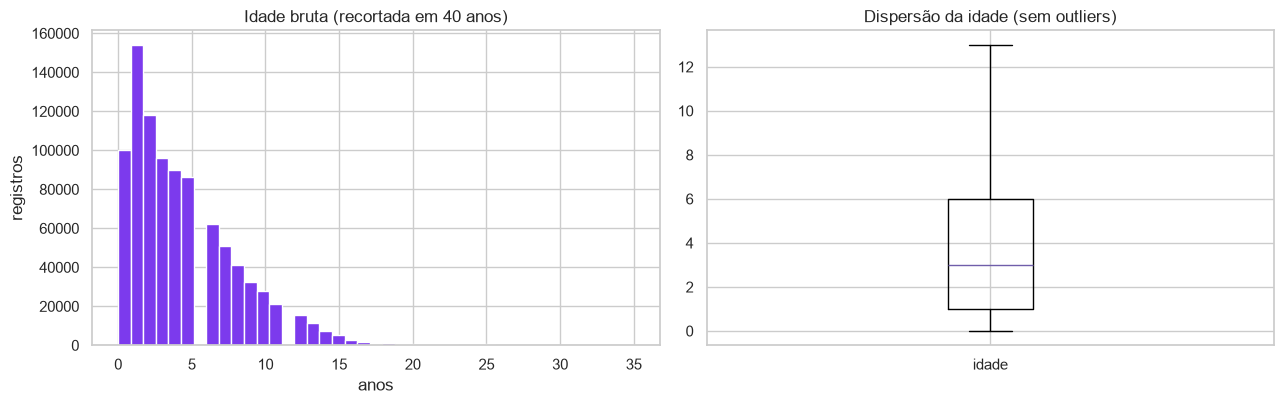

In [6]:
# distribuição da idade: a cauda longa é o que justifica o corte em 30 anos
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.2))
eixos[0].hist(idade.dropna().clip(upper=40), bins=41, color="#7C3AED")
eixos[0].set_title("Idade bruta (recortada em 40 anos)")
eixos[0].set_xlabel("anos")
eixos[0].set_ylabel("registros")

eixos[1].boxplot([idade.dropna()], tick_labels=["idade"], showfliers=False)
eixos[1].set_title("Dispersão da idade (sem outliers)")
plt.tight_layout()
plt.savefig(FIGURAS / "qualidade_idade.png", dpi=130, bbox_inches="tight")
plt.show()

## 3. Estatística descritiva

**Responsável: Eduardo Ferro**

Medidas de tendência central e de dispersão antes de qualquer teste: média e
mediana para saber se a distribuição é simétrica, desvio padrão e coeficiente de
variação para medir o quanto os grupos diferem, e comparação entre cão e gato.

In [7]:
numericas = cadastros[["idade"]].describe(percentiles=[.1, .25, .5, .75, .9]).T
numericas["amplitude"] = cadastros["idade"].max() - cadastros["idade"].min()
numericas["coef_var_%"] = 100 * cadastros["idade"].std() / cadastros["idade"].mean()
numericas["assimetria"] = cadastros["idade"].skew()
numericas["curtose"] = cadastros["idade"].kurt()
numericas.round(2)

,count,mean,std,min,10%,25%,50%,75%,90%,max,amplitude,coef_var_%,assimetria,curtose
idade,928202.0,4.35,3.83,0.0,0.0,1.0,3.0,6.0,10.0,30.0,30.0,88.12,1.4,3.06


In [8]:
por_especie = (cadastros.groupby("especie")["idade"]
               .agg(n="size", media="mean", mediana="median", desvio="std",
                    q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75)))
por_especie["coef_var_%"] = 100 * por_especie["desvio"] / por_especie["media"]
por_especie.round(2)

,n,media,mediana,desvio,q1,q3,coef_var_%
especie,,,,,,,
Cão,587458,4.74,4.0,3.91,2.0,7.0,82.45
Gato,341207,3.69,3.0,3.62,1.0,5.0,97.99


In [9]:
categoricas = pd.DataFrame({
    "categoria": cadastros["especie"].value_counts().index.tolist()
                 + cadastros["sexo"].value_counts().index.tolist(),
    "n": cadastros["especie"].value_counts().tolist()
         + cadastros["sexo"].value_counts().tolist(),
})
categoricas["%"] = (100 * categoricas["n"] / len(cadastros)).round(1)
categoricas

,categoria,n,%
0,Cão,587458,63.3
1,Gato,341207,36.7
2,Fêmea,487429,52.5
3,Macho,441236,47.5


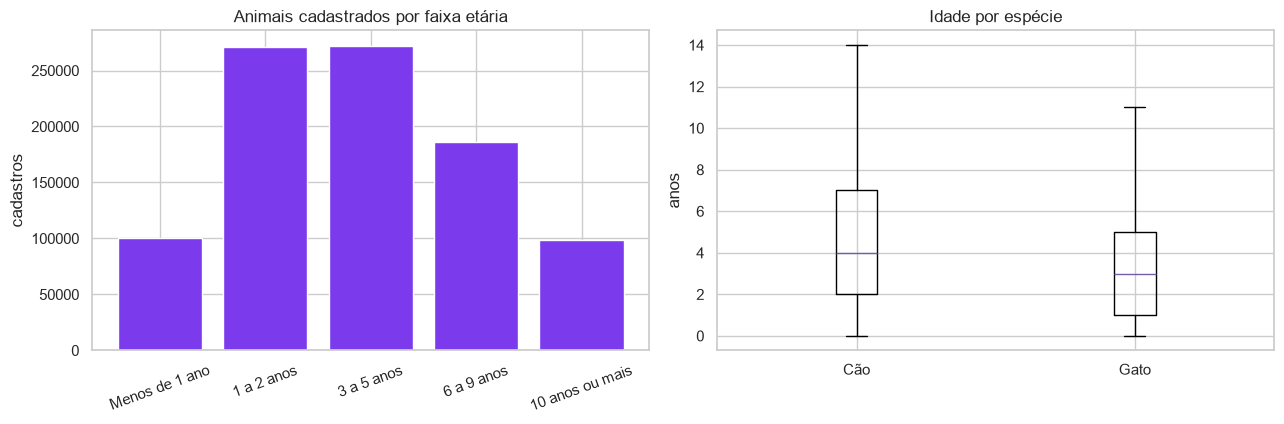

In [10]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.4))

ordem = ["Menos de 1 ano", "1 a 2 anos", "3 a 5 anos", "6 a 9 anos",
         "10 anos ou mais"]
contagem = cadastros["faixa_etaria"].value_counts().reindex(ordem)
eixos[0].bar(contagem.index, contagem.values, color="#7C3AED")
eixos[0].set_title("Animais cadastrados por faixa etária")
eixos[0].set_ylabel("cadastros")
eixos[0].tick_params(axis="x", rotation=20)

dados = [cadastros.loc[cadastros["especie"] == e, "idade"].dropna()
         for e in ["Cão", "Gato"]]
eixos[1].boxplot(dados, tick_labels=["Cão", "Gato"], showfliers=False)
eixos[1].set_title("Idade por espécie")
eixos[1].set_ylabel("anos")

plt.tight_layout()
plt.savefig(FIGURAS / "descritiva_cadastros.png", dpi=130, bbox_inches="tight")
plt.show()

### Leitura da descritiva

- A distribuição de idade é **assimétrica à direita**: mediana de 3 anos, média
  de 4,35 e desvio de ~3,9. Ou seja, a maior parte dos cadastros é de animais
  jovens, com uma cauda de animais idosos puxando a média para cima.
- **Cão 63,3% × gato 36,7%.** Em capitais o gato passa de 40% — em Fortaleza,
  44,6%.
- **52,5% fêmeas**, coerente com a procura maior por castração de fêmeas.
- Filhotes (menos de 1 ano) são **10,8%** — o cadastro é feito majoritariamente
  em animais já adultos, o que é justamente o alvo da campanha de castração.

## 4. Técnica 1 — Teste de hipóteses

**Pergunta:** a cobertura do cadastro cresce com o porte do município?

- **H0:** a cobertura mediana é igual entre municípios pequenos e grandes.
- **H1:** as distribuições diferem.
- **Teste:** Mann-Whitney bilateral (não paramétrico — a cobertura é assimétrica),
  α = 0,05, com correlação de Spearman e tamanho de efeito.

In [11]:
valido = municipios[municipios["populacao"] > 0].dropna(subset=["cobertura_por_100k"])
mediana_pop = valido["populacao"].median()
pequenos = valido.loc[valido["populacao"] <= mediana_pop, "cobertura_por_100k"]
grandes = valido.loc[valido["populacao"] > mediana_pop, "cobertura_por_100k"]

u = stats.mannwhitneyu(pequenos, grandes, alternative="two-sided")
rho = stats.spearmanr(valido["populacao"], valido["cobertura_por_100k"])

print(f"municípios no teste: {len(valido):,}".replace(",", "."))
print(f"mediana populacional: {mediana_pop:,.0f} hab.".replace(",", "."))
print(f"cobertura mediana — menores: {pequenos.median():.1f} / 100 mil")
print(f"cobertura mediana — maiores: {grandes.median():.1f} / 100 mil")
print(f"Mann-Whitney p = {u.pvalue:.2e}")
print(f"Spearman rho = {rho.statistic:.3f} (p = {rho.pvalue:.2e})")
print("decisão:", "rejeitar H0" if u.pvalue < 0.05 else "não rejeitar H0")

municípios no teste: 5.397
mediana populacional: 11.758 hab.
cobertura mediana — menores: 157.6 / 100 mil
cobertura mediana — maiores: 252.5 / 100 mil
Mann-Whitney p = 1.38e-120
Spearman rho = 0.394 (p = 7.39e-200)
decisão: rejeitar H0


In [12]:
def cohen_d(a, b):
    n1, n2 = len(a), len(b)
    pooled = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))
    return (a.mean() - b.mean()) / pooled

d = cohen_d(pequenos, grandes)
efeito = "pequeno" if abs(d) < 0.2 else ("médio" if abs(d) < 0.5 else "grande")
print(f"d de Cohen = {d:.3f} → efeito {efeito}")

d de Cohen = -0.486 → efeito médio


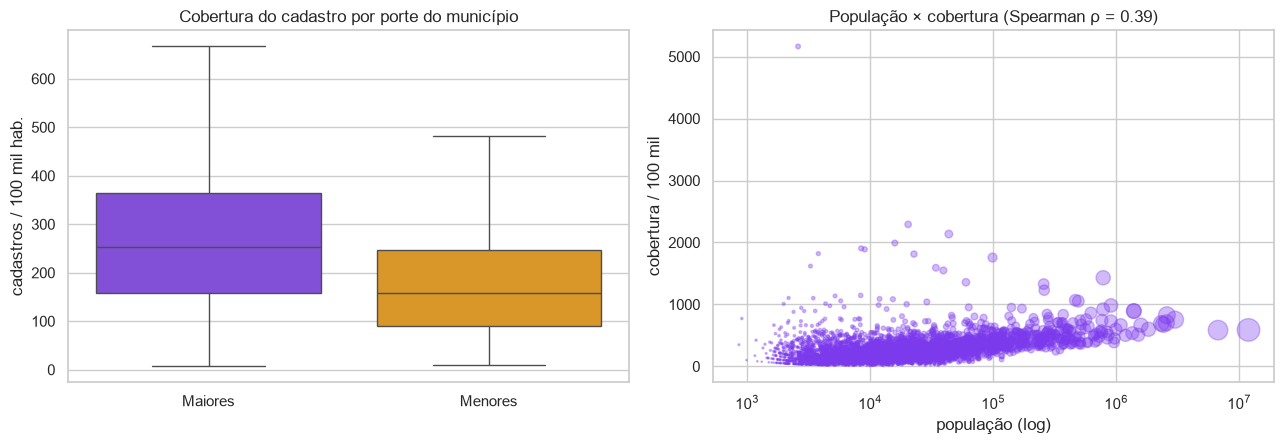

In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.6))

rotulo = np.where(valido["populacao"] <= mediana_pop, "Menores", "Maiores")
sns.boxplot(x=rotulo, y=valido["cobertura_por_100k"], hue=rotulo,
            ax=eixos[0], palette=["#7C3AED", "#F59E0B"], legend=False,
            showfliers=False)
eixos[0].set_title("Cobertura do cadastro por porte do município")
eixos[0].set_ylabel("cadastros / 100 mil hab.")

eixos[1].scatter(valido["populacao"], valido["cobertura_por_100k"],
                 s=np.sqrt(valido["cadastros"]), alpha=0.35, color="#7C3AED")
eixos[1].set_xscale("log")
eixos[1].set_xlabel("população (log)")
eixos[1].set_ylabel("cobertura / 100 mil")
eixos[1].set_title(f"População × cobertura (Spearman ρ = {rho.statistic:.2f})")

plt.tight_layout()
plt.savefig(FIGURAS / "teste_cobertura.png", dpi=130, bbox_inches="tight")
plt.show()

### Conclusão do teste

**Rejeitamos H0**: municípios maiores têm cobertura sistematicamente maior
(252 contra 158 por 100 mil, p ≈ 1,4e-120, ρ = 0,39, efeito médio).

A leitura para o projeto é direta: **a política chega primeiro onde a máquina
administrativa já existe**. Município pequeno depende de campanha itinerante e
de mutirão — e é exatamente aí que a plataforma tem valor, porque consegue
registrar demanda onde não há posto fixo.

É associação, não causalidade: porte é proxy de estrutura de vigilância e de
capacidade de campanha, não a causa do cadastro.

## 5. Técnica 2 — Probabilidade

Probabilidade empírica e condicional sobre a mesma base: qual a chance de um
cadastro ser de gato, de filhote, e como isso muda por região.

In [14]:
total = len(cadastros)
p_gato = cadastros["especie"].eq("Gato").mean()
p_filhote = cadastros["filhote"].fillna(False).mean()
p_gato_filhote = cadastros.loc[cadastros["filhote"].fillna(False), "especie"].eq("Gato").mean()
p_filhote_gato = cadastros.loc[cadastros["especie"].eq("Gato"), "filhote"].fillna(False).mean()

print(f"P(gato) ................ {100 * p_gato:.2f}%")
print(f"P(filhote) ............. {100 * p_filhote:.2f}%")
print(f"P(gato | filhote) ...... {100 * p_gato_filhote:.2f}%")
print(f"P(filhote | gato) ...... {100 * p_filhote_gato:.2f}%")

P(gato) ................ 36.74%
P(filhote) ............. 10.76%
P(gato | filhote) ...... 46.68%
P(filhote | gato) ...... 13.67%


In [15]:
# tabela de contingência: P(faixa etária | espécie) em %
pd.crosstab(cadastros["faixa_etaria"], cadastros["especie"],
            normalize="columns").mul(100).round(1)

especie,Cão,Gato
faixa_etaria,,
1 a 2 anos,26.0,34.7
10 anos ou mais,12.3,7.5
3 a 5 anos,30.0,28.1
6 a 9 anos,22.5,16.0
Ignorado,0.1,0.0
Menos de 1 ano,9.1,13.7


In [16]:
# probabilidade por região: onde o gato é mais provável
por_uf = (municipios.groupby("uf")
          .apply(lambda g: pd.Series({
              "cadastros": g["cadastros"].sum(),
              "p_gato_%": 100 * g["cadastros_gato"].sum() / max(g["cadastros"].sum(), 1),
              "p_filhote_%": np.average(g["pct_filhote"], weights=g["cadastros"]),
          }), include_groups=False)
          .sort_values("p_gato_%", ascending=False))
por_uf.head(10).round(1)

,cadastros,p_gato_%,p_filhote_%
uf,,,
AP,6301.0,46.9,21.5
SE,11395.0,45.7,9.5
PB,18180.0,45.5,10.8
AL,11141.0,43.2,10.8
CE,48000.0,43.1,10.9
PA,32014.0,42.2,13.2
RN,20182.0,41.5,10.5
MA,18952.0,40.8,14.4
AM,19702.0,40.7,13.2


## 6. Técnica 3 (complementar) — Correlação e integração de fontes

Aqui as duas fontes se encontram: **cadastro** (SinPatinhas) e **demanda por
atendimento** (SINAN/antirrábico). A pergunta é se municípios com mais agressão
registrada são os que mais cadastram — ou se existe descompasso.

In [17]:
cruzado = municipios.dropna(subset=["cobertura_por_100k", "demanda_por_100k"])
cruzado = cruzado[cruzado["populacao"] >= 20_000]

rho_cruz = stats.spearmanr(cruzado["cobertura_por_100k"], cruzado["demanda_por_100k"])
print(f"municípios cruzados: {len(cruzado):,}".replace(",", "."))
print(f"Spearman cobertura × demanda: rho = {rho_cruz.statistic:.3f} "
      f"(p = {rho_cruz.pvalue:.2e})")

municípios cruzados: 1.751
Spearman cobertura × demanda: rho = 0.121 (p = 4.05e-07)


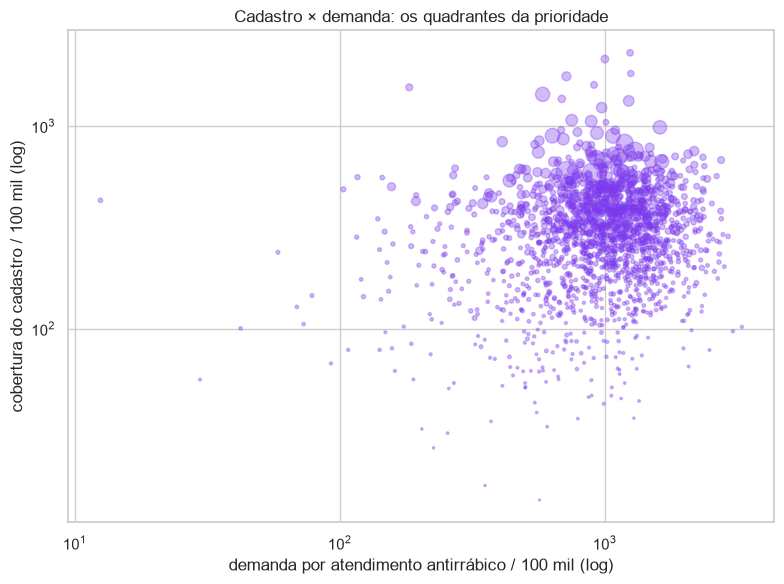

In [18]:
plt.figure(figsize=(8, 6))
plt.scatter(cruzado["demanda_por_100k"], cruzado["cobertura_por_100k"],
            s=np.sqrt(cruzado["cadastros"]), alpha=0.35, color="#7C3AED")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("demanda por atendimento antirrábico / 100 mil (log)")
plt.ylabel("cobertura do cadastro / 100 mil (log)")
plt.title("Cadastro × demanda: os quadrantes da prioridade")
plt.tight_layout()
plt.savefig(FIGURAS / "cadastro_vs_demanda.png", dpi=130, bbox_inches="tight")
plt.show()

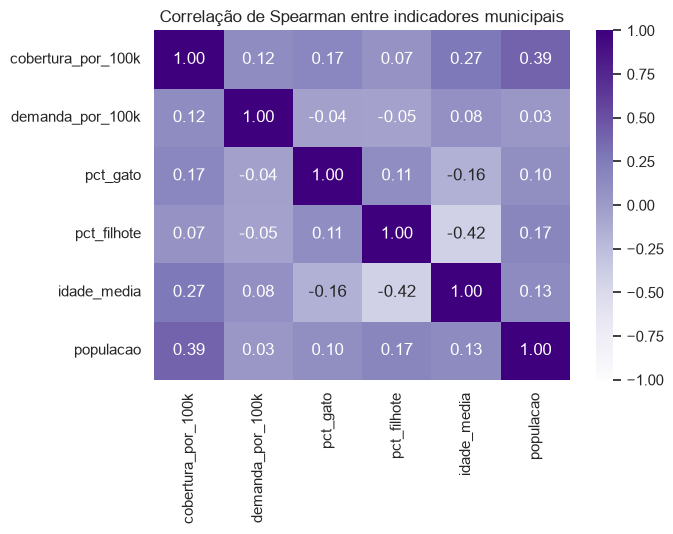

In [19]:
corr = municipios[["cobertura_por_100k", "demanda_por_100k", "pct_gato",
                   "pct_filhote", "idade_media", "populacao"]].corr(method="spearman")
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Purples", vmin=-1, vmax=1)
plt.title("Correlação de Spearman entre indicadores municipais")
plt.tight_layout()
plt.savefig(FIGURAS / "correlacao.png", dpi=130, bbox_inches="tight")
plt.show()

### 6.2 Alcance sobre os domicílios que têm animal

O denominador que faltava. As tabelas **4930 e 4931 do SIDRA/IBGE** informam
quantos domicílios brasileiros declaram ter cão ou gato. Com isso o cadastro
deixa de ser comparado com "habitantes" — uma base que não diz nada sobre
animais — e passa a ser comparado com **quem tem animal em casa**: a população
que a política precisa alcançar.

A PNAD não é representativa em nível municipal (só capitais), então esta
comparação é feita por UF. É a leitura mais dura do projeto: quantos cães já
entraram no sistema para cada cem domicílios que têm cão.

In [20]:
domicilios = pd.read_csv(PROCESSADOS / "domicilios_animais_uf.csv")
domicilios = domicilios[domicilios["ano"] == domicilios["ano"].max()]

alcance = (municipios.groupby("uf")
           .agg(cadastros_cao=("cadastros_cao", "sum"),
                cadastros_gato=("cadastros_gato", "sum"))
           .reset_index()
           .merge(domicilios, on="uf", how="left"))
alcance["cao_por_100_dom"] = 100 * alcance["cadastros_cao"] / alcance["domicilios_cao"]
alcance["gato_por_100_dom"] = 100 * alcance["cadastros_gato"] / alcance["domicilios_gato"]

resumo_alcance = pd.Series({
    "domicílios com cão": alcance["domicilios_cao"].sum(),
    "cães cadastrados": alcance["cadastros_cao"].sum(),
    "cães por 100 domicílios com cão":
        100 * alcance["cadastros_cao"].sum() / alcance["domicilios_cao"].sum(),
    "domicílios com gato": alcance["domicilios_gato"].sum(),
    "gatos cadastrados": alcance["cadastros_gato"].sum(),
    "gatos por 100 domicílios com gato":
        100 * alcance["cadastros_gato"].sum() / alcance["domicilios_gato"].sum(),
})
resumo_alcance.round(2).to_frame("valor")

,valor
domicílios com cão,33754348.00
cães cadastrados,587458.00
cães por 100 domicílios com cão,1.74
domicílios com gato,14143568.00
gatos cadastrados,341207.00
gatos por 100 domicílios com gato,2.41


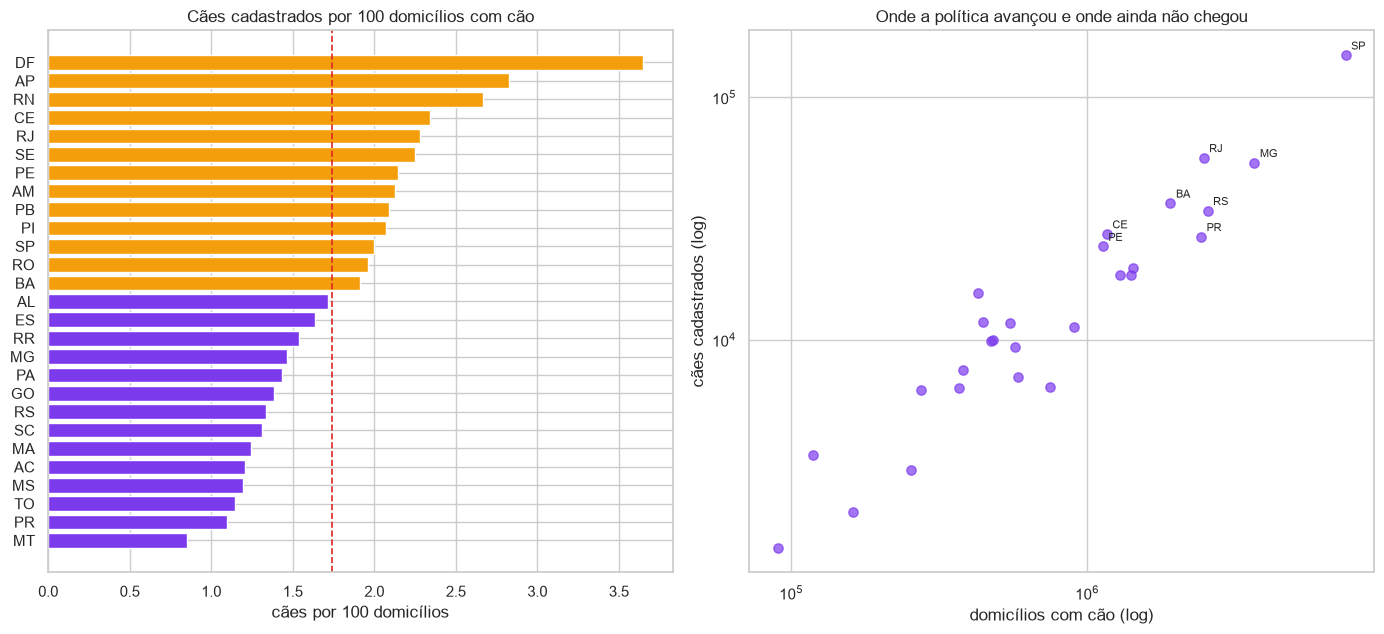

In [21]:
ordenado = alcance.dropna(subset=["cao_por_100_dom"]).sort_values("cao_por_100_dom")
media = 100 * alcance["cadastros_cao"].sum() / alcance["domicilios_cao"].sum()
cores = ["#F59E0B" if v > media else "#7C3AED" for v in ordenado["cao_por_100_dom"]]

fig, eixos = plt.subplots(1, 2, figsize=(14, 6.5))
eixos[0].barh(ordenado["uf"], ordenado["cao_por_100_dom"], color=cores)
eixos[0].axvline(media, color="#DC2626", ls="--", lw=1.2)
eixos[0].set_title("Cães cadastrados por 100 domicílios com cão")
eixos[0].set_xlabel("cães por 100 domicílios")

melhores = alcance.nlargest(8, "cadastros_cao")
eixos[1].scatter(alcance["domicilios_cao"], alcance["cadastros_cao"],
                 s=45, color="#7C3AED", alpha=0.7)
for _, linha in melhores.iterrows():
    eixos[1].annotate(linha["uf"], (linha["domicilios_cao"], linha["cadastros_cao"]),
                      fontsize=8, xytext=(4, 4), textcoords="offset points")
eixos[1].set_xscale("log"); eixos[1].set_yscale("log")
eixos[1].set_xlabel("domicílios com cão (log)")
eixos[1].set_ylabel("cães cadastrados (log)")
eixos[1].set_title("Onde a política avançou e onde ainda não chegou")

plt.tight_layout()
plt.savefig(FIGURAS / "alcance_domicilios.png", dpi=130, bbox_inches="tight")
plt.show()

**Leitura.** O país tem **33,8 milhões de domicílios com cão** e **14,1 milhões
com gato**; o SinPatinhas tem 587 mil cães e 341 mil gatos cadastrados. São
**1,7 cão e 2,4 gatos por cem domicílios** — ou seja, a política de cadastro
alcançou menos de 2% dos lares que têm cão. É a medida mais honesta do estágio
em que o programa está, e a razão pela qual a plataforma precisa de campo
(campanha, mutirão, agente de saúde) e não só de aplicativo.

A dispersão entre UFs também importa: onde o cadastro por domicílio é maior, a
estrutura municipal já existia; onde é menor, é onde o VetSolidário entra.

## 7. Machine Learning — agrupamento de municípios

K-Means sobre indicadores padronizados, com escolha de k por silhueta. Não é
previsão: é priorização — cada cluster recebe uma recomendação operacional.

In [22]:
variaveis = ["cobertura_por_100k", "pct_gato", "pct_filhote", "idade_media"]
dados_ml = municipios[(municipios["populacao"] >= 20_000)
                      & municipios[variaveis].notna().all(axis=1)].copy()
X = StandardScaler().fit_transform(dados_ml[variaveis])

silhuetas = {}
for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    silhuetas[k] = silhouette_score(X, modelo.labels_)
pd.Series(silhuetas).round(3).rename("silhueta").to_frame()

,silhueta
2,0.293
3,0.229
4,0.233
5,0.246
6,0.223


In [23]:
melhor_k = int(max(silhuetas, key=silhuetas.get))
modelo = KMeans(n_clusters=melhor_k, random_state=42, n_init=10).fit(X)
dados_ml["cluster"] = modelo.labels_
print(f"k escolhido: {melhor_k} (silhueta = {silhuetas[melhor_k]:.3f})")

perfis = dados_ml.groupby("cluster")[variaveis + ["populacao"]].mean().round(1)
perfis["municipios"] = dados_ml.groupby("cluster").size()
perfis.sort_values("cobertura_por_100k")

k escolhido: 2 (silhueta = 0.293)


,cobertura_por_100k,pct_gato,pct_filhote,idade_media,populacao,municipios
cluster,,,,,,
1,225.3,38.6,17.3,3.1,46483.4,644
0,368.5,33.7,9.6,4.3,137418.7,1107


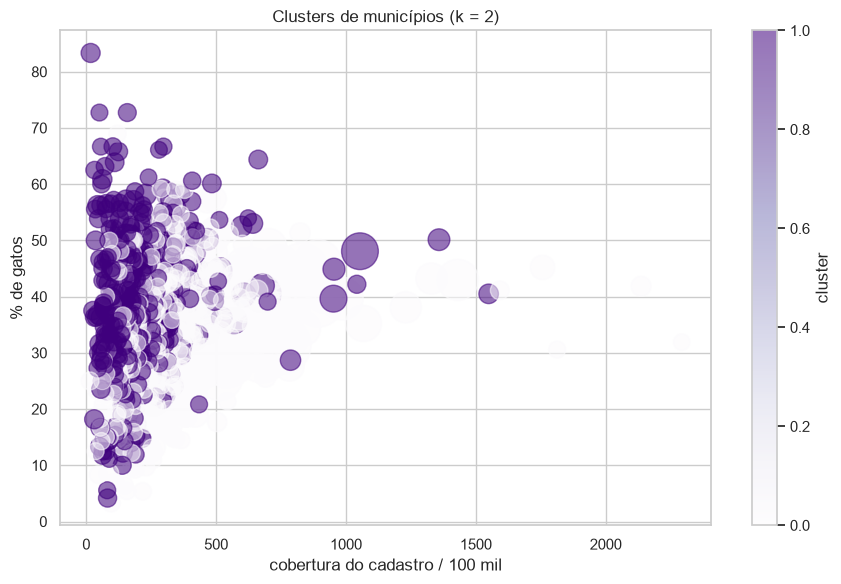

In [24]:
plt.figure(figsize=(9, 6))
dispersao = plt.scatter(dados_ml["cobertura_por_100k"], dados_ml["pct_gato"],
                        c=dados_ml["cluster"], s=np.sqrt(dados_ml["populacao"]),
                        cmap="Purples", alpha=0.55)
plt.xlabel("cobertura do cadastro / 100 mil")
plt.ylabel("% de gatos")
plt.title(f"Clusters de municípios (k = {melhor_k})")
plt.colorbar(dispersao, label="cluster")
plt.tight_layout()
plt.savefig(FIGURAS / "clusters.png", dpi=130, bbox_inches="tight")
plt.show()

In [25]:
fila = (municipios[municipios["populacao"] >= 100_000]
        .nlargest(15, "indice_prioridade")
        [["municipio", "uf", "populacao", "cobertura_por_100k",
          "demanda_por_100k", "indice_prioridade"]])
fila

,municipio,uf,populacao,cobertura_por_100k,demanda_por_100k,indice_prioridade
544,Balsas,MA,106332,199.38,2327.62,75.5
330,Trindade,GO,156197,259.29,1676.73,70.3
80,Boa Vista,RR,500965,354.72,2265.63,70.2
280,Caxias,MA,163650,298.20,1871.68,70.0
380,Itumbiara,GO,114331,302.63,1736.19,69.2
316,Maranguape,CE,108323,398.81,2164.82,68.7
281,Patos de Minas,MG,170404,284.03,1444.21,68.1
362,Piraquara,PR,129035,284.42,1431.39,68.0
394,Ipojuca,PE,107370,308.28,1529.29,67.9
390,Araguari,MG,123959,270.25,1335.12,67.8


## 8. Conclusões e limitações

**O que os dados mostram**

1. **928.665 animais** cadastrados em **5.397 municípios** entre abril e
   dezembro de 2025 — cobertura nacional de **435 por 100 mil habitantes**.
2. O cadastro estreou com 504 mil registros em abril e estabilizou em ~45–50 mil
   por mês: a base mede **adesão a uma política nova**, não um estoque histórico.
3. **Cão 63,3% · gato 36,7%**, fêmeas 52,5%, idade mediana de 3 anos — o
   cadastro é feito em animal adulto, o que reforça o foco em castração.
4. A cobertura **cresce com o porte do município** (ρ = 0,39, p ≈ 1,4e-120):
   174 municípios ainda não têm nenhum cadastro.
5. Cruzando com a demanda antirrábica aparece o descompasso que a plataforma
   resolve: municípios com muita agressão registrada e pouca cobertura de
   cadastro — a fila de prioridade do dashboard.

**Limitações**

- O SinPatinhas registra **animais cadastrados**, não atendimentos, castrações ou
  resgates: a camada operacional da plataforma é simulada e está rotulada como tal
  no app, no README e no notebook.
- A base cobre **nove meses** de uma política em implantação; qualquer tendência
  aqui é curta e não deve ser extrapolada.
- Sem variável socioeconômica (renda, saneamento) não é possível separar adesão
  de capacidade administrativa — próximo passo é o Censo 2022 via SIDRA.
- Granularidade municipal: bairro não existe nos microdados publicados.

**Próximos passos**

- incorporar renda e cobertura de atenção básica como controles;
- modelar a cobertura com regressão (GLM binomial) e comparar com o K-Means;
- acompanhar a série mensal conforme o MMA publicar novas competências.

In [26]:
saida = PROCESSADOS / "tabelas_notebook"
saida.mkdir(parents=True, exist_ok=True)
por_especie.round(2).to_csv(saida / "descritiva_por_especie.csv")
perfis.to_csv(saida / "clusters.csv")
fila.to_csv(saida / "fila_prioridade.csv", index=False)
print("tabelas exportadas em", saida)

tabelas exportadas em C:\Users\Eduardo Ferro\Desktop\VetSolidario\dados\processados\tabelas_notebook
